### Import packages

In [ ]:
from pathlib import Path
import ee
import geemap
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold, cross_val_score, permutation_test_score)

### Connect to GEE 

In [ ]:
# Authenticate and connect to GEE API
ee.Authenticate()  
ee.Initialize(project="cottoncondition")

### Define Parameters 

In [ ]:
START, END = "2022-04-01", "2022-11-30"
LABELS_SHP_PATH = r"C:\Users\donle\Desktop\SmallPAK\02 Data\Labels\Important_Labels.shp"

SCALE = 10                 # m
BUFFER_M = 5              # inward buffer in m (check against Raab)
MIN_PIXELS = 5             # ignore observations with fewer valid pixels in the field
CLOUD_PCT_THRESHOLD = 90
S1_ORBIT_PASS, S1_REL_ORBIT = "ASCENDING", 71
FREQ = "2W"                # resample frequency for ML input

S2_BANDS, S1_BANDS = ["NDVI", "NDRE"], ["VV", "VH"]
BANDS = S2_BANDS + S1_BANDS

CACHE = Path(f"cache\ts_{S1_ORBIT_PASS}{S1_REL_ORBIT}_buf{BUFFER_M}_{START}_{END}.csv")

### Load Field Boundaries and Labels

In [83]:
fields = gpd.read_file(LABELS_SHP_PATH).to_crs(epsg=4326)

# Drop fields that are flagged and reindex
fields = fields[fields["flag"] != 1.0].dropna(subset=["leaf_con", "canopy_den", "a_leaf_con", "a_cnpy_den"])
fields["field_id"] = fields.index

# inward buffer, computed in a metric CRS
fields["geometry"] = fields.to_crs(fields.estimate_utm_crs()).buffer(-BUFFER_M).to_crs(4326)

# define aoi and convert fields to ee.FeatureCollection
aoi = ee.Geometry.Rectangle(list(fields.total_bounds))
fields_fc = geemap.geopandas_to_ee(fields[["field_id", "geometry"]])

### Define S1 and S2

In [84]:
# Function for masking clouds in 
def mask_s2(img):
    mask = img.select("SCL").remap([4, 5, 6, 11], [1, 1, 1, 1], 0)
    return img.updateMask(mask).divide(10000).copyProperties(img, ["system:time_start"])


# Function for adding indices
def add_indices(image):
    ndvi = image.normalizedDifference(["B8", "B4"]).rename("NDVI")
    ndre = image.normalizedDifference(["B8", "B5"]).rename("NDRE")
    evi = image.expression("2.5 * ((NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 1))",
        {"NIR": image.select("B8"),"RED": image.select("B4"),"BLUE": image.select("B2")}).rename("EVI")
    # ndmi = image.normalizedDifference(["B8", "B11"]).rename("NDMI")
    
    return image.addBands([ndvi, ndre, evi]) #, ndmi])


In [85]:
s2 = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
      .filterBounds(aoi).filterDate(START, END)
      .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", CLOUD_PCT_THRESHOLD))
      .map(mask_s2).map(add_indices))

s1 = (ee.ImageCollection("COPERNICUS/S1_GRD")
      .filterBounds(aoi).filterDate(START, END)
      .filter(ee.Filter.eq("instrumentMode", "IW"))
      .filter(ee.Filter.eq("orbitProperties_pass", S1_ORBIT_PASS))
      .filter(ee.Filter.eq("relativeOrbitNumber_start", S1_REL_ORBIT))
      .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
      .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH")))


In [86]:
REDUCER = (ee.Reducer.median()
        #    .combine(ee.Reducer.mean(), sharedInputs=True)
            .combine(ee.Reducer.stdDev(), sharedInputs=True)
           .combine(ee.Reducer.count(), sharedInputs=True)
           )


def field_timeseries(collection, bands):
    """One row per field and scene (footprint contains the field): pixel mean, std and count."""
    def per_field(f):
        geom = f.geometry()
        scenes = collection.filter(ee.Filter.contains(".geo", geom)).select(bands)
        return ee.FeatureCollection(scenes.map(lambda img: ee.Feature(None, img.reduceRegion(REDUCER, geom, SCALE)
            .set("field_id", f.get("field_id")).set("date", img.date().format("YYYY-MM-dd")))))
    return fields_fc.map(per_field).flatten()


def download_ts(collection, bands):
    """Download in monthly chunks to stay within GEE limits."""
    edges = pd.date_range(START, END, freq="MS").union(pd.to_datetime([START, END])).strftime("%Y-%m-%d")
    chunks = [pd.DataFrame([f["properties"] for f in field_timeseries(collection.filterDate(a, b), bands).getInfo()["features"]])
              for a, b in zip(edges[:-1], edges[1:])]
    return pd.concat(chunks, ignore_index=True)

In [87]:
if CACHE.exists():
    ts = pd.read_csv(CACHE, parse_dates=["date"])
else:
    # overlapping tiles: keep the S2 scene with more valid pixels
    s2_ts = download_ts(s2, S2_BANDS).sort_values("NDVI_count").drop_duplicates(["field_id", "date"], keep="last")
    s1_ts = download_ts(s1, S1_BANDS)
    ts = s2_ts.merge(s1_ts, on=["field_id", "date"], how="outer", validate="one_to_one").sort_values(["field_id", "date"])   
    ts["date"] = pd.to_datetime(ts["date"])
    ts.to_csv(CACHE, index=False)

In [ ]:
# Invalidate observations with too few valid pixels, before any aggregation
for b in BANDS:
    low = ts[f"{b}_count"] < MIN_PIXELS
    ts.loc[low, [f"{b}_median", f"{b}_stdDev"]] = float("nan")

4


### Define Functions for loading Collections

In [112]:
def field_statistics(ts, cutoff=None):
    """Season statistics per field from observations up to `cutoff` (whole season if None)."""
    d = ts if cutoff is None else ts[ts["date"] <= cutoff]
    out = {}
    for b in BANDS:
        s = (d.pivot_table(index="date", columns="field_id", values=f"{b}_median")   # changed: ts is already masked, no filter here
               .resample("D").mean().interpolate(limit_area="inside")
               .rolling(15, center=True, min_periods=1).median())      # daily, smoothed
        slope = s.diff()                                               # change per day
        out |= {f"{b}_mean": s.mean(), f"{b}_max": s.max(),
                f"{b}_rise": slope.max(),
                # f"{b}_fall": slope.min(),
                f"{b}_dev": d.groupby("field_id")[f"{b}_stdDev"].mean()   # changed
                }
    return pd.DataFrame(out).reindex(fields.index)

In [113]:
field_stats = field_statistics(ts)

In [114]:
ts["date"] = pd.to_datetime(ts["date"])

bands = ts.columns[ts.columns.str.endswith("_median")].tolist()


bi_weekly_ts = (ts.groupby(
       ["field_id", pd.Grouper(key="date", freq=FREQ)])[bands].median()
       .unstack("date"))
bi_weekly_ts.columns = [f"{b}_{d:%m%d}" for b, d in bi_weekly_ts.columns]

In [115]:
ts

,NDRE_count,NDRE_median,NDRE_stdDev,NDVI_count,NDVI_median,NDVI_stdDev,date,field_id,VH_count,VH_median,VH_stdDev,VV_count,VV_median,VV_stdDev
0,59.0,0.158273,0.026746,59.0,0.246507,0.026627,2022-04-05,0,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,2022-04-07,0,55.0,-19.459407,3.287677,55.0,-15.334267,2.826884
2,59.0,0.139456,0.031385,59.0,0.215989,0.024169,2022-04-10,0,NaN,NaN,NaN,NaN,NaN,NaN
3,59.0,0.140014,0.032254,59.0,0.207045,0.032151,2022-04-15,0,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,2022-04-19,0,58.0,-25.649553,2.730314,58.0,-18.075636,2.724460
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4472,NaN,NaN,NaN,NaN,NaN,NaN,2022-11-09,87,24.0,-14.407419,1.760155,24.0,-8.760281,1.081425
4473,27.0,0.288932,0.049185,27.0,0.435502,0.044697,2022-11-11,87,NaN,NaN,NaN,NaN,NaN,NaN
4474,27.0,0.184596,0.069160,27.0,0.226359,0.093483,2022-11-16,87,NaN,NaN,NaN,NaN,NaN,NaN
4475,27.0,0.166667,0.084891,27.0,0.209208,0.086397,2022-11-21,87,24.0,-15.513415,1.714045,24.0,-6.505847,1.515495


In [116]:
cnt = pd.concat({b: bi_weekly_ts.filter(regex=f"^{b}_").isna().sum().rename(lambda c: c.rsplit("_", 1)[-1]) for b in ["NDVI", "VV"]}, axis=1)
cnt[cnt.sum(axis=1) > 0]

,NDVI,VV
0403,67,71
0710,5,0
0724,1,0
0807,62,0
0821,5,0
1211,67,71


In [117]:
# Drop band-date columns where more than 60 % of the observations are missing
bi_weekly_ts = bi_weekly_ts.loc[:, bi_weekly_ts.isna().mean() <= 0.6]

In [118]:
print(ts[ts["NDVI_count"] >= MIN_PIXELS].dropna(subset=["NDVI_median"]).groupby("field_id").size().describe().round(1))

count    71.0
mean     41.1
std       7.6
min      36.0
25%      38.5
50%      40.0
75%      41.0
max      75.0
dtype: float64


In [119]:
bi_weekly_ts

,NDRE_median_0417,NDRE_median_0501,NDRE_median_0515,NDRE_median_0529,NDRE_median_0612,NDRE_median_0626,NDRE_median_0710,NDRE_median_0724,NDRE_median_0821,NDRE_median_0904,...,VV_median_0724,VV_median_0807,VV_median_0821,VV_median_0904,VV_median_0918,VV_median_1002,VV_median_1016,VV_median_1030,VV_median_1113,VV_median_1127
field_id,,,,,,,,,,,,,,,,,,,,,
0,0.140014,0.062196,0.057627,0.071768,0.117665,0.199431,0.171412,0.254258,0.315426,0.430464,...,-9.150865,-8.824079,-7.826739,-9.672075,-8.615581,-10.285898,-10.290589,-11.122925,-8.194362,-15.011290
1,0.070827,0.054446,0.039763,0.058059,0.064690,0.142620,0.180161,NaN,0.358197,0.363507,...,-9.350645,-8.808362,-8.928350,-7.729874,-10.341323,-10.794930,-13.082190,-13.521816,-10.647393,-13.400996
4,0.111713,0.069811,0.029733,0.038121,0.084019,0.206137,0.228402,0.327210,0.364105,0.341528,...,-8.277995,-9.290736,-6.457236,-7.809812,-10.072553,-8.501642,-10.847005,-13.147834,-13.969327,-11.070584
5,0.112832,0.077619,0.040151,0.033815,0.094229,0.140679,0.168339,0.334045,0.374909,0.394731,...,-6.571178,-8.608900,-8.363805,-4.931911,-7.691155,-7.024223,-6.379896,-8.208622,-8.134259,-7.880347
6,0.094620,0.051429,0.041682,0.106106,0.153176,0.160141,0.314927,0.491187,0.498421,0.461921,...,-9.450988,-6.387565,-11.055070,-9.253270,-10.135210,-11.672028,-11.185131,-12.201303,-8.026054,-8.584413
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,0.068847,0.115778,0.196139,0.213048,0.287633,0.350935,0.441026,0.539721,0.487548,0.558868,...,-8.837562,-7.638973,-8.853166,-7.792184,-8.457968,-7.972740,-9.117406,-9.982276,-10.788974,-8.611286
82,0.113702,0.060773,0.033948,0.058809,0.132590,0.228977,0.186778,0.324037,0.325328,0.368993,...,-7.533462,-8.028858,-6.780320,-7.889809,-9.131680,-8.256942,-9.493011,-9.941084,-11.026054,-6.620708
84,0.100880,0.048621,0.051013,0.043900,0.051747,0.072148,0.118483,0.215388,0.254311,0.325831,...,-9.344555,-8.343861,-8.515743,-8.580230,-9.956649,-8.454550,-9.123689,-11.399073,-9.701342,-7.551480


## Data Preparation for ML

#### Load and analyse Labels - Variable for label type and rater

In [97]:
from sklearn.model_selection import train_test_split

X = bi_weekly_ts
y = fields["a_cnpy_den"] > 0    # canopy 0 vs 1,2}

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [98]:
rf = RandomForestClassifier(n_estimators=100, random_state=39)   # handles NaN natively (sklearn >= 1.4)
rf.fit(X_train, y_train)
rf.score(X_test, y_test)

0.7272727272727273

In [99]:
def cv_scores(X, y, scoring, n_repeats=5):
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_repeats, random_state=0)
    return cross_val_score(rf, X, y, cv=cv, scoring=scoring, n_jobs=-1)

ts_cols_s2 = [c for c in bi_weekly_ts if c.split("_")[0] in S2_BANDS]
ts_cols_s1 = [c for c in bi_weekly_ts if c.split("_")[0] in S1_BANDS]

stats_cols_s2 = [c for c in field_stats if c.split("_")[0] in S2_BANDS]
stats_cols_s1 = [c for c in field_stats if c.split("_")[0] in S1_BANDS]

sets = {"S2 ts": bi_weekly_ts[ts_cols_s2],
        "S1 ts": bi_weekly_ts[ts_cols_s1],
        "S1+S2 ts": bi_weekly_ts[ts_cols_s1 + ts_cols_s2],
        "S2 stats": field_stats[stats_cols_s2],
        "S1 stats": field_stats[stats_cols_s1],
        "S1+S2 stats": field_stats[stats_cols_s1 + stats_cols_s2],
        "all": pd.concat([bi_weekly_ts, field_stats], axis=1)
        }

rows = []
for sname, Xs in sets.items():
    acc = cv_scores(Xs, y, "accuracy")
    rows.append({
        "features": sname,
        "target": "class",
        "Acc": f"{acc.mean():.3f} ± {acc.std():.3f}"
    })
pd.DataFrame(rows).set_index(["features", "target"]).unstack("target").loc[list(sets)]



,Acc
target,class
features,
S2 ts,0.724 ± 0.118
S1 ts,0.647 ± 0.112
S1+S2 ts,0.730 ± 0.128
S2 stats,0.823 ± 0.090
S1 stats,0.580 ± 0.120
S1+S2 stats,0.739 ± 0.123
all,0.682 ± 0.114


## Some tests for feature importance

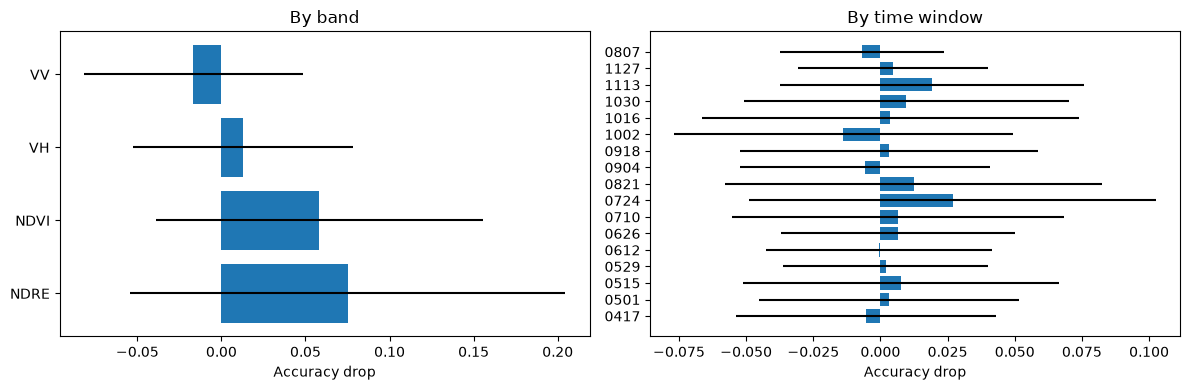

In [100]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold

X = bi_weekly_ts  # or bi_weekly_ts for S1+S2

band = lambda c: c.split("_")[0]
window = lambda c: c.split("_")[-1]

def group_importance(X, y, groups, n_repeats=10, seed=0):
    rng = np.random.default_rng(seed)
    drops = {g: [] for g in groups}
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=seed)
    for train, test in cv.split(X, y):
        rf = RandomForestClassifier(n_estimators=100, random_state=seed).fit(X.iloc[train], y.iloc[train])
        X_test, y_test = X.iloc[test], y.iloc[test]
        base = rf.score(X_test, y_test)
        for g, cols in groups.items():
            for _ in range(n_repeats):
                Xp = X_test.copy()
                Xp[cols] = Xp[cols].iloc[rng.permutation(len(Xp))].to_numpy()
                drops[g].append(base - rf.score(Xp, y_test))
    return pd.Series({g: np.mean(d) for g, d in drops.items()}), pd.Series({g: np.std(d) for g, d in drops.items()})

def groups_by(key):
    out = {}
    for c in X.columns:
        out.setdefault(key(c), []).append(c)
    return out

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (title, key) in zip(axes, {"By band": band, "By time window": window}.items()):
    m, s = group_importance(X, y, groups_by(key))
    ax.barh(m.index, m.values, xerr=s.values)
    ax.set_title(title)
    ax.set_xlabel("Accuracy drop")
plt.tight_layout()
plt.show()

## Visualisations

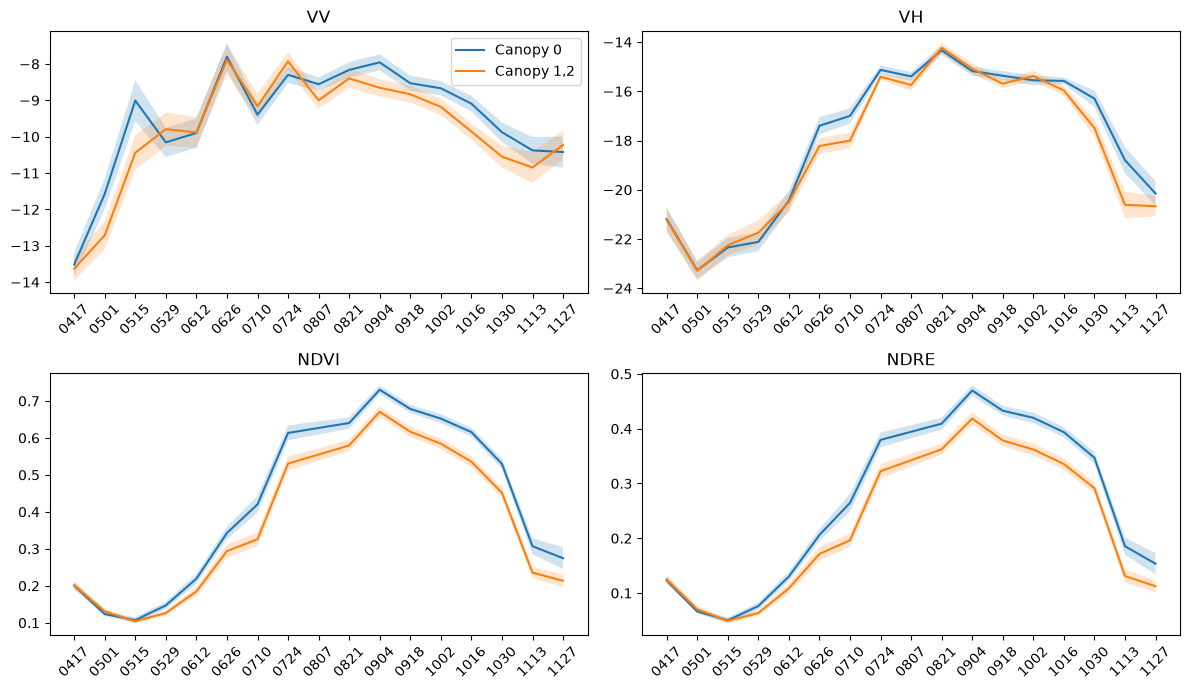

In [101]:
import matplotlib.pyplot as plt

bands = ["VV", "VH", "NDVI", "NDRE"]
long = bi_weekly_ts.assign(cls=y.values).melt(id_vars="cls", var_name="col", value_name="v")
long["band"] = long.col.str.split("_").str[0]
long["window"] = long.col.str.split("_").str[-1]

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, b in zip(axes.flat, bands):
    g = long[long.band == b].groupby(["cls", "window"]).v.agg(["mean", "sem"]).reset_index()
    for cls, label in {0: "Canopy 0", 1: "Canopy 1,2"}.items():
        d = g[g.cls == cls].sort_values("window")
        ax.plot(d.window, d["mean"], label=label)
        ax.fill_between(d.window, d["mean"] - d["sem"], d["mean"] + d["sem"], alpha=0.2)
    ax.set_title(b)
axes[0, 0].legend()
# plt.setp(axes[-1], xticks=axes[-1, 0].get_xticks())

for ax in axes.flat:
    ax.tick_params(axis="x", labelrotation=45, labelbottom=True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

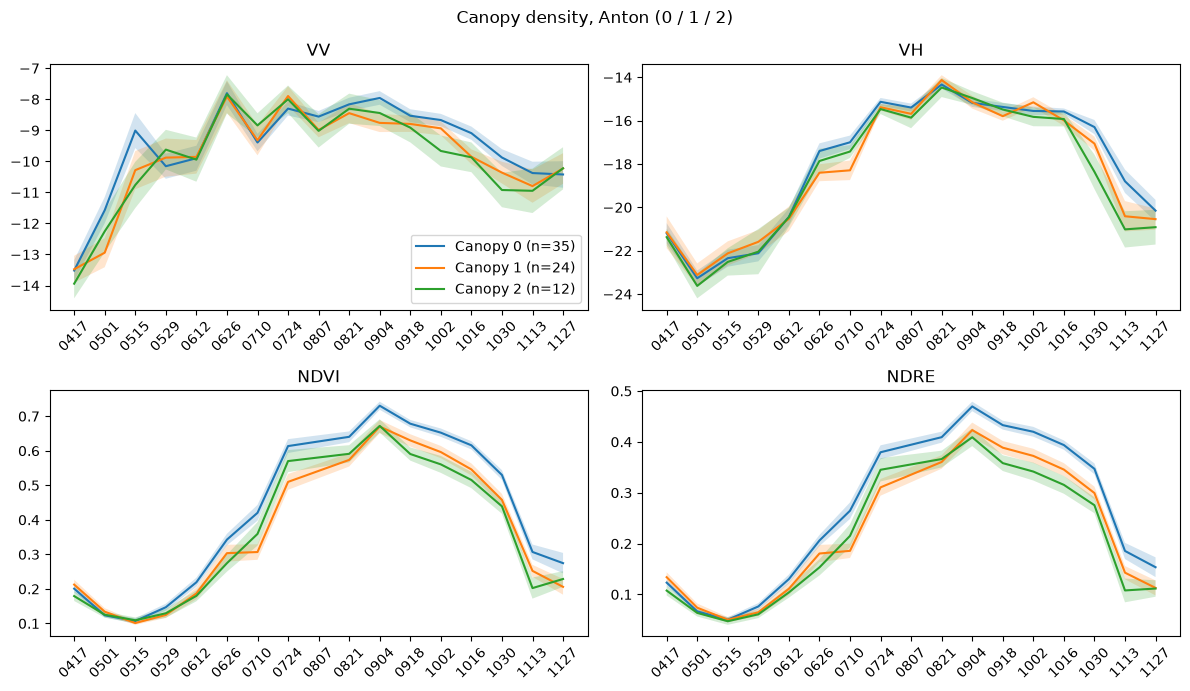

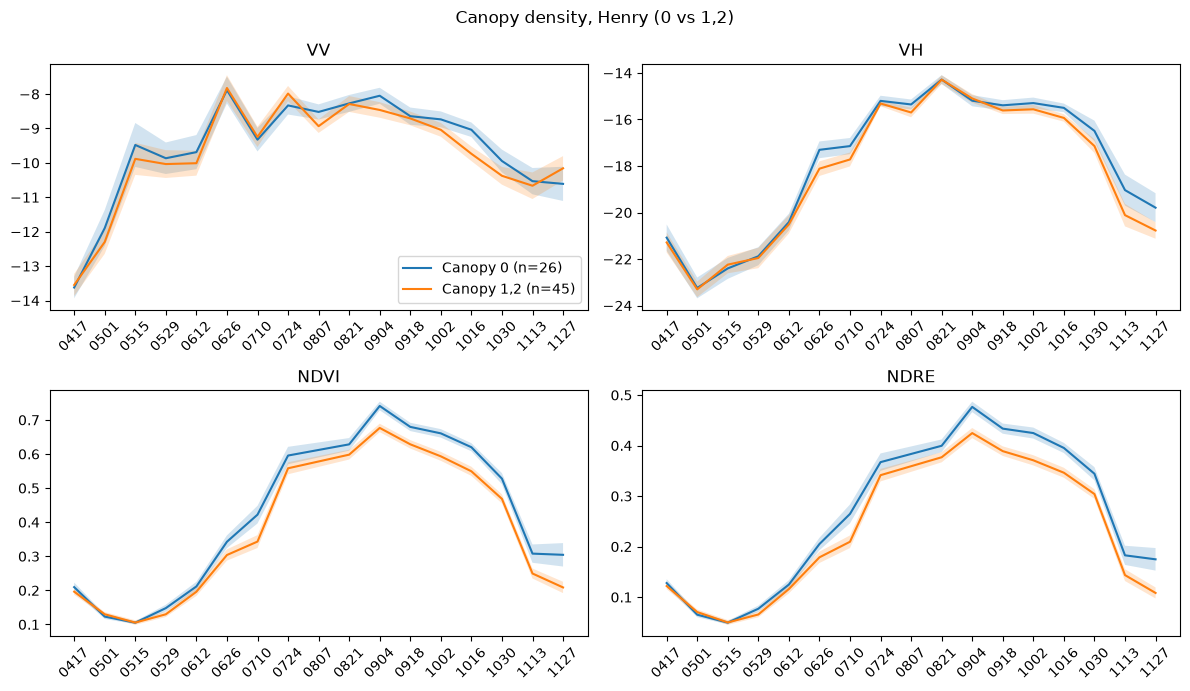

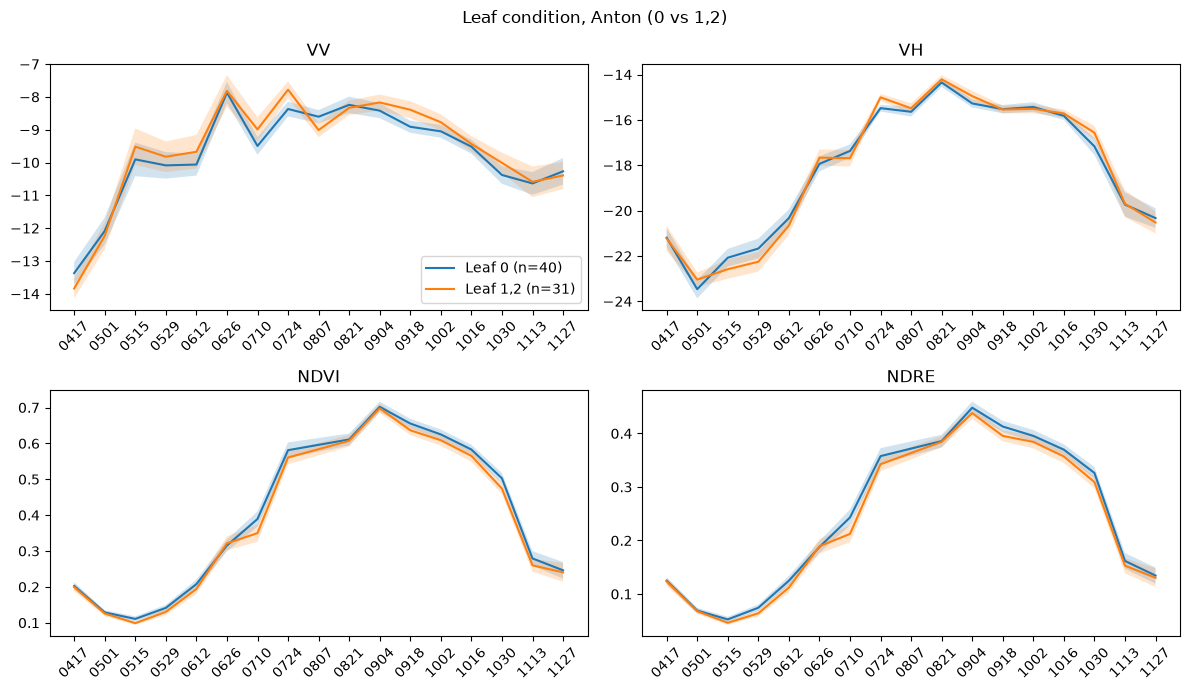

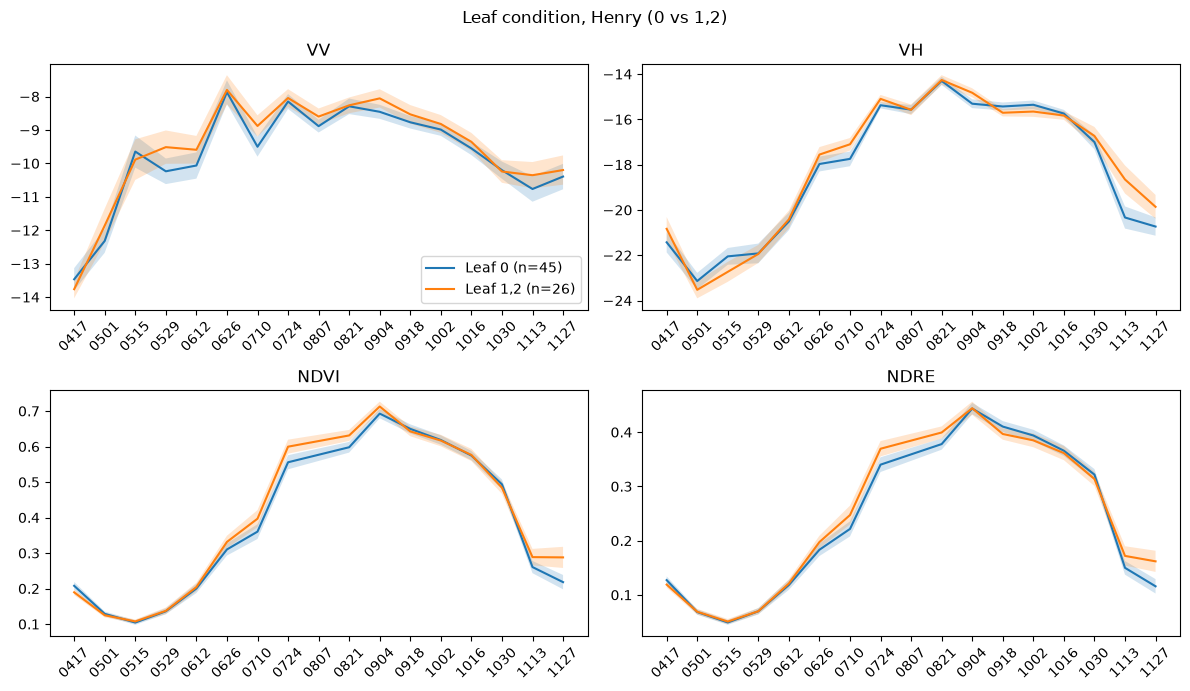

In [122]:
import matplotlib.pyplot as plt

bands = ["VV", "VH", "NDVI", "NDRE"]


def plot_classes(labels, class_names, title):
    labels = labels.reindex(bi_weekly_ts.index)   # align by field_id instead of position
    long = bi_weekly_ts.assign(cls=labels).melt(id_vars="cls", var_name="col", value_name="v")
    long["band"] = long["col"].str.split("_").str[0]
    long["window"] = long["col"].str.split("_").str[-1]

    fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
    for ax, b in zip(axes.flat, bands):
        g = long[long["band"] == b].groupby(["cls", "window"])["v"].agg(["mean", "sem"]).reset_index()
        for cls, name in class_names.items():
            d = g[g["cls"] == cls].sort_values("window")
            ax.plot(d["window"], d["mean"], label=f"{name} (n={(labels == cls).sum()})")
            ax.fill_between(d["window"], d["mean"] - d["sem"], d["mean"] + d["sem"], alpha=0.2)
        ax.set_title(b)
        ax.tick_params(axis="x", labelrotation=45, labelbottom=True)
    axes[0, 0].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_classes(fields["a_cnpy_den"], {0: "Canopy 0", 1: "Canopy 1", 2: "Canopy 2"}, "Canopy density, Anton (0 / 1 / 2)")
plot_classes(fields["canopy_den"] > 0, {False: "Canopy 0", True: "Canopy 1,2"}, "Canopy density, Henry (0 vs 1,2)")
plot_classes(fields["a_leaf_con"] > 0, {False: "Leaf 0", True: "Leaf 1,2"}, "Leaf condition, Anton (0 vs 1,2)")
plot_classes(fields["leaf_con"] > 0, {False: "Leaf 0", True: "Leaf 1,2"}, "Leaf condition, Henry (0 vs 1,2)")

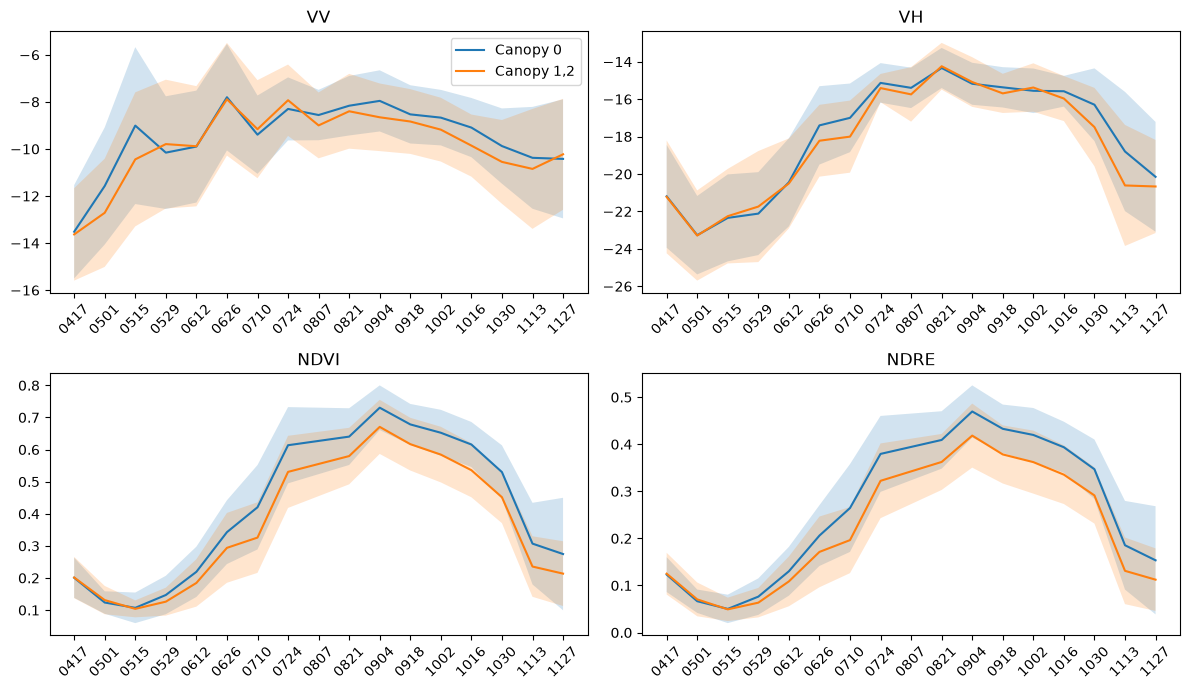

In [102]:

import matplotlib.pyplot as plt

bands = ["VV", "VH", "NDVI", "NDRE"]
long = bi_weekly_ts.assign(cls=y.values).melt(
    id_vars="cls", var_name="col", value_name="v"
)
long["band"] = long.col.str.split("_").str[0]
long["window"] = long.col.str.split("_").str[-1]

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)

for ax, b in zip(axes.flat, bands):
    g = (
        long[long.band == b]
        .groupby(["cls", "window"]).v
        .agg(["mean", "std"])
        .reset_index()
    )

    for cls, label in {0: "Canopy 0", 1: "Canopy 1,2"}.items():
        d = g[g.cls == cls].sort_values("window")
        ax.plot(d.window, d["mean"], label=label)
        ax.fill_between(
            d.window,
            d["mean"] - d["std"],
            d["mean"] + d["std"],
            alpha=0.2
        )

    ax.set_title(b)

axes[0, 0].legend()

for ax in axes.flat:
    ax.tick_params(axis="x", labelrotation=45, labelbottom=True)

plt.tight_layout()
plt.show()


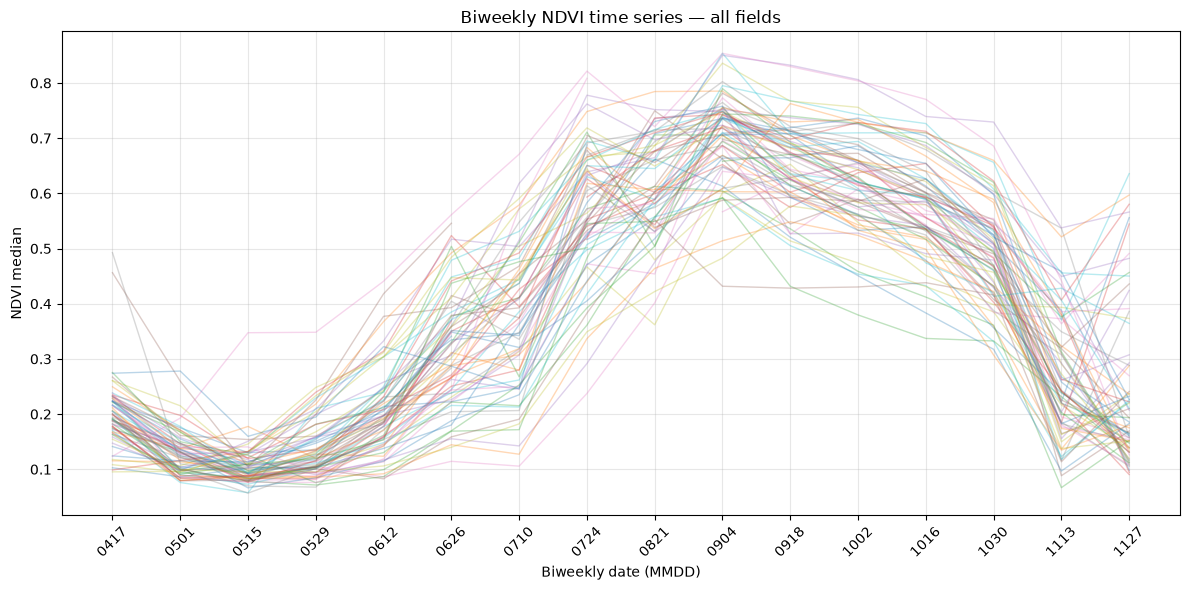

In [104]:

import matplotlib.pyplot as plt

ndvi_cols = sorted(
    [c for c in bi_weekly_ts.columns if c.startswith("NDVI_median_")],
    key=lambda c: c.rsplit("_", 1)[-1]
)

dates = [c.rsplit("_", 1)[-1] for c in ndvi_cols]

plt.figure(figsize=(12, 6))

for _, row in bi_weekly_ts[ndvi_cols].iterrows():
    plt.plot(dates, row.values, alpha=0.3, linewidth=1)

plt.xlabel("Biweekly date (MMDD)")
plt.ylabel("NDVI median")
plt.title("Biweekly NDVI time series — all fields")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


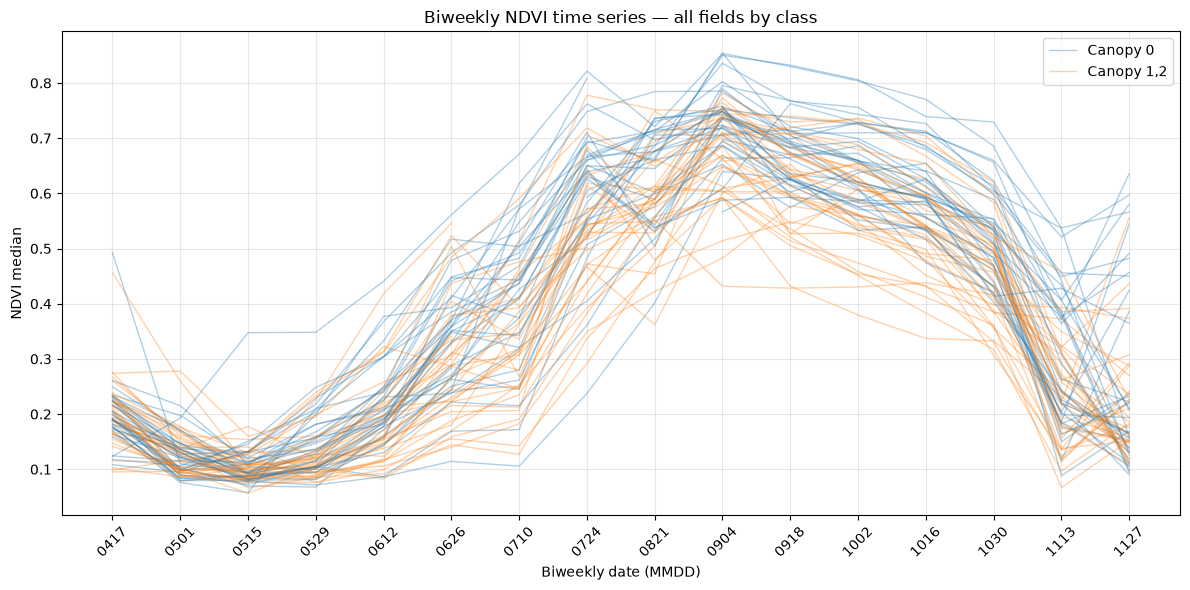

In [105]:

import matplotlib.pyplot as plt

ndvi_cols = sorted(
    [c for c in bi_weekly_ts.columns if c.startswith("NDVI_median_")],
    key=lambda c: c.rsplit("_", 1)[-1]
)

dates = [c.rsplit("_", 1)[-1] for c in ndvi_cols]

labels = y.values
class_colors = {0: "tab:blue", 1: "tab:orange"}
class_names = {0: "Canopy 0", 1: "Canopy 1,2"}

plt.figure(figsize=(12, 6))

for i, (_, row) in enumerate(bi_weekly_ts[ndvi_cols].iterrows()):
    cls = labels[i]
    plt.plot(
        dates,
        row.values,
        color=class_colors[cls],
        alpha=0.35,
        linewidth=1,
        label=class_names[cls] if cls not in labels[:i] else None
    )

plt.xlabel("Biweekly date (MMDD)")
plt.ylabel("NDVI median")
plt.title("Biweekly NDVI time series — all fields by class")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


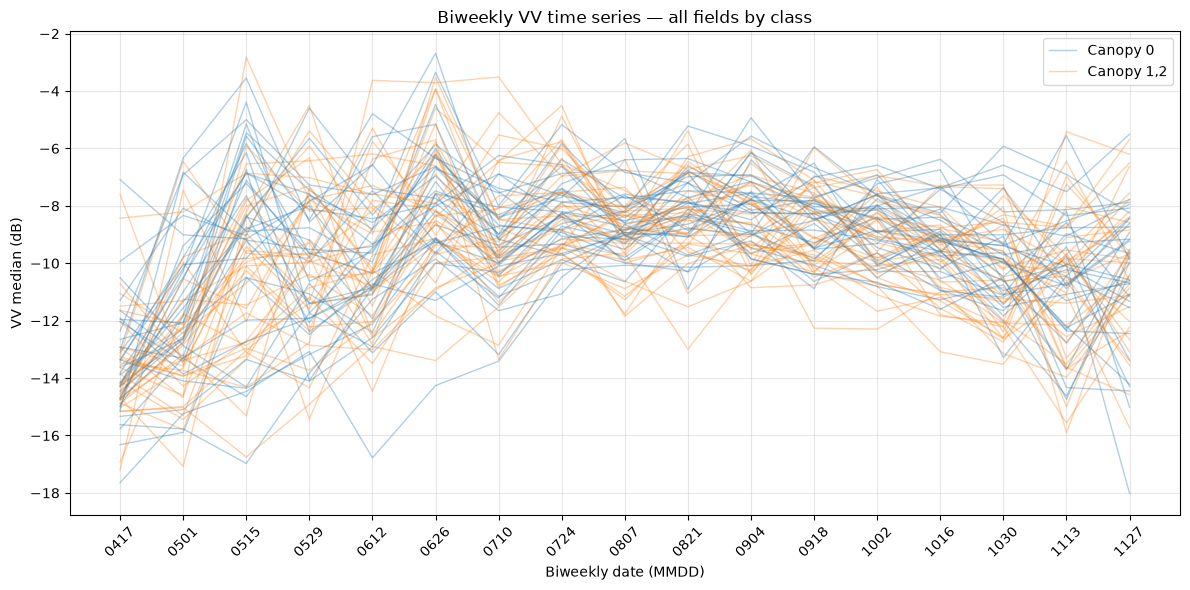

In [106]:

import matplotlib.pyplot as plt

vv_cols = sorted(
    [c for c in bi_weekly_ts.columns if c.startswith("VV_median_")],
    key=lambda c: c.rsplit("_", 1)[-1]
)

dates = [c.rsplit("_", 1)[-1] for c in vv_cols]

labels = y.values
class_colors = {0: "tab:blue", 1: "tab:orange"}
class_names = {0: "Canopy 0", 1: "Canopy 1,2"}

plt.figure(figsize=(12, 6))

for i, (_, row) in enumerate(bi_weekly_ts[vv_cols].iterrows()):
    cls = labels[i]
    plt.plot(
        dates,
        row.values,
        color=class_colors[cls],
        alpha=0.35,
        linewidth=1,
        label=class_names[cls] if cls not in labels[:i] else None
    )

plt.xlabel("Biweekly date (MMDD)")
plt.ylabel("VV median (dB)")
plt.title("Biweekly VV time series — all fields by class")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [107]:
field_stats

,NDVI_mean,NDVI_max,NDVI_rise,NDRE_mean,NDRE_max,NDRE_rise,VV_mean,VV_max,VV_rise,VH_mean,VH_max,VH_rise
0,0.385269,0.685872,0.016456,0.237488,0.451059,0.010840,-11.013401,-8.242297,0.496265,-17.487281,-12.989334,0.436867
1,0.335918,0.618269,0.018139,0.196196,0.368275,0.013248,-10.195684,-7.451208,0.919104,-19.809337,-15.179166,0.579840
4,0.340957,0.662766,0.047092,0.187504,0.380747,0.024999,-10.840746,-7.020809,0.464432,-18.473168,-12.888118,0.351610
5,0.386894,0.677768,0.028005,0.238883,0.421483,0.018273,-8.051022,-5.851659,0.347735,-17.986991,-13.787139,0.551549
6,0.441966,0.825167,0.041482,0.263338,0.527895,0.025412,-10.323469,-7.554441,0.347937,-17.819746,-14.026093,0.305679
...,...,...,...,...,...,...,...,...,...,...,...,...
80,0.552183,0.834291,0.032948,0.354620,0.547366,0.021129,-8.674367,-7.102207,0.181474,-16.371097,-14.481598,0.183453
82,0.374502,0.630865,0.026065,0.217301,0.365500,0.016616,-9.993621,-6.876256,0.445836,-19.670154,-14.379749,0.450644
84,0.294504,0.576232,0.020977,0.180753,0.359659,0.007191,-10.020258,-6.731593,0.622384,-18.889298,-14.768822,0.427851
86,0.439824,0.736405,0.039377,0.276155,0.478082,0.019670,-8.044846,-5.439848,0.544013,-16.896620,-14.290934,0.392313


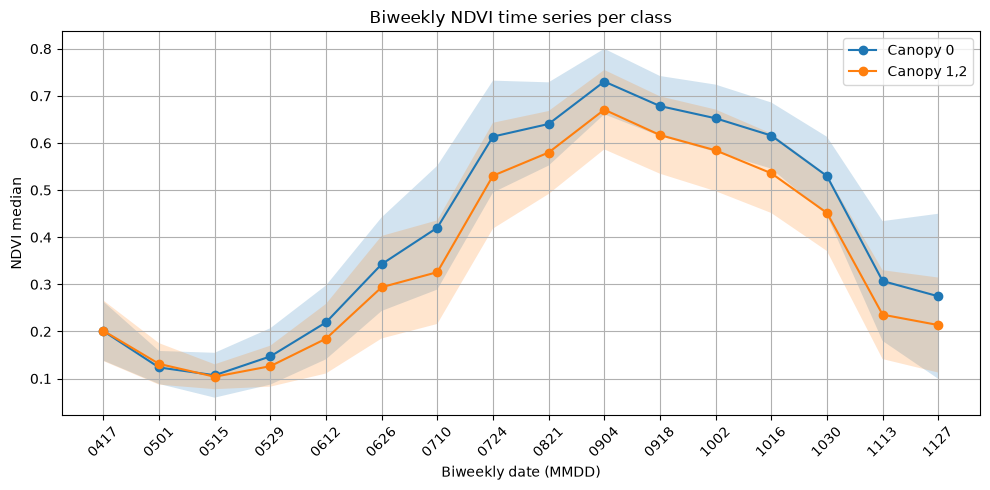

In [108]:

import matplotlib.pyplot as plt
import pandas as pd

ndvi_cols = sorted(
    [c for c in bi_weekly_ts.columns if c.startswith("NDVI_median_")],
    key=lambda c: c.rsplit("_", 1)[-1]
)

dates = [c.rsplit("_", 1)[-1] for c in ndvi_cols]

plot_df = bi_weekly_ts[ndvi_cols].copy()
plot_df["cls"] = y.values

x = range(len(dates))

plt.figure(figsize=(10, 5))

for cls, label in {0: "Canopy 0", 1: "Canopy 1,2"}.items():
    values = plot_df.loc[plot_df["cls"] == cls, ndvi_cols]

    mean = values.mean(axis=0)
    std = values.std(axis=0)

    plt.plot(x, mean, marker="o", label=label)
    plt.fill_between(x, mean - std, mean + std, alpha=0.2)

plt.xticks(x, dates, rotation=45)
plt.xlabel("Biweekly date (MMDD)")
plt.ylabel("NDVI median")
plt.title("Biweekly NDVI time series per class")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


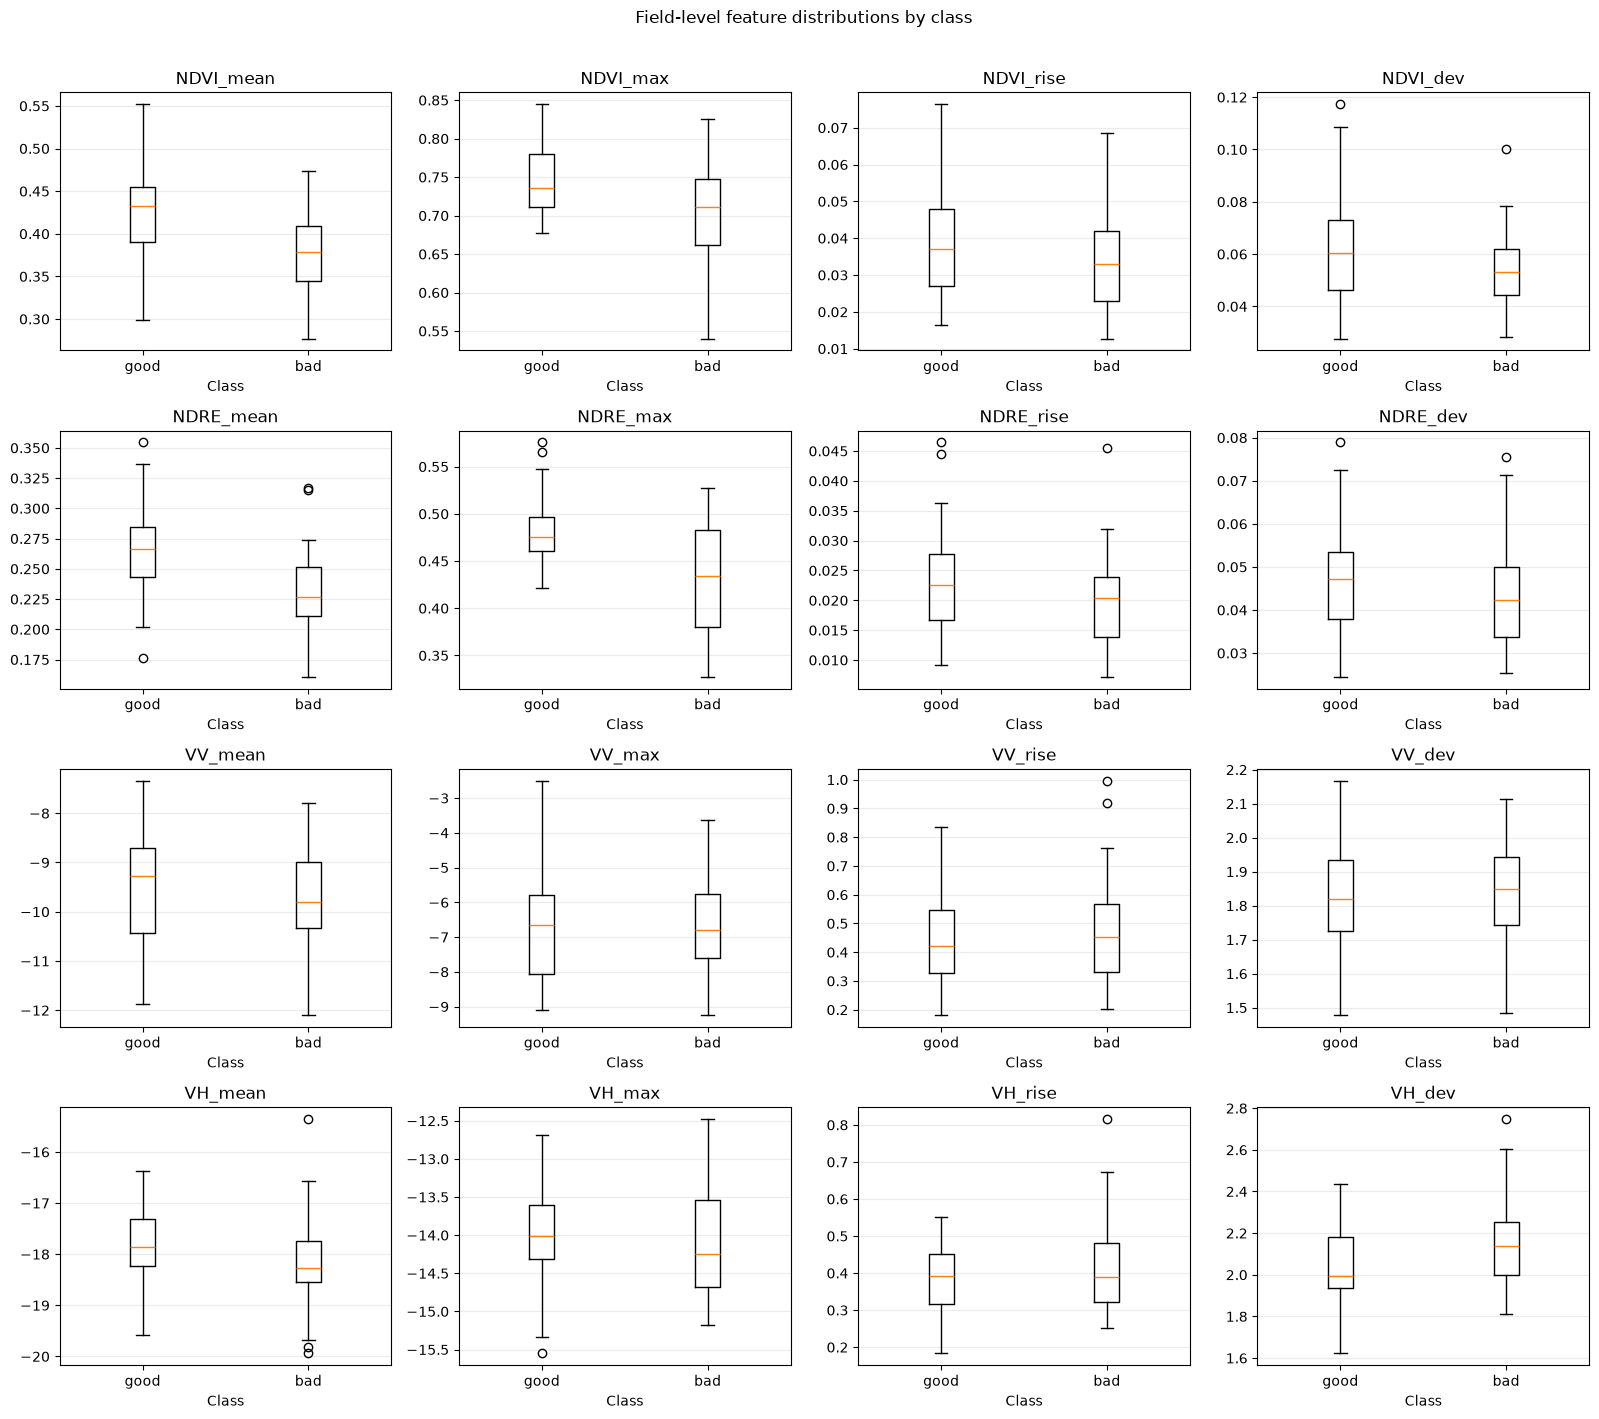

In [121]:

import matplotlib.pyplot as plt


features = [
    "NDVI_mean", "NDVI_max", "NDVI_rise", "NDVI_dev",
    "NDRE_mean", "NDRE_max", "NDRE_rise", "NDRE_dev",
    "VV_mean", "VV_max", "VV_rise", "VV_dev",
    "VH_mean", "VH_max", "VH_rise", "VH_dev",
]

plot_df = field_stats[features].copy()
plot_df["class"] = y.values

classes = sorted(plot_df["class"].dropna().unique())

plot_df["class"] = plot_df["class"].map({
    False: "good",
    True: "bad"
})

classes = ["good", "bad"]


colors = ["tab:blue", "tab:orange"]

fig, axes = plt.subplots(4, 4, figsize=(16, 14))

for ax, feature in zip(axes.flat, features):
    data = [
        plot_df.loc[plot_df["class"] == cls, feature].dropna()
        for cls in classes
    ]

    ax.boxplot(data, tick_labels=[str(c) for c in classes])
    ax.set_title(feature)
    ax.set_xlabel("Class")
    ax.grid(axis="y", alpha=0.25)

plt.suptitle("Field-level feature distributions by class", y=1.01)
plt.tight_layout()
plt.show()
